# C05 · Mức độ tập trung đối tác thương mại

**Câu hỏi Q2.** Mức độ tập trung đối tác của Việt Nam thay đổi thế nào theo thời gian?

**Lâm Thanh Nghi** · Mở notebook trong dự án đã giải nén có cài các thư viện từ `requirements.txt` và chọn **Run All** để tạo hai hình.

Dùng quy tắc mã đối tác của bộ định dạng dự án. Loại nhóm BACI `490 / S19` (*Các nền kinh tế châu Á khác, chưa phân loại*) và mã tổng hợp khỏi cả bảng xếp hạng lẫn mẫu số. Tính tỷ trọng theo từng năm và từng chiều thương mại.

## C05A · Xu hướng chỉ số tập trung đối tác

- **Task** · (Q2.3) Theo dõi HHI xuất khẩu và nhập khẩu.
- **Dạng** · Biểu đồ đường 2005–2024, có nhãn ở hai đầu mỗi đường.
- **Lý do** · Hai đường cho thấy diễn biến tập trung trên toàn bộ đối tác qua các năm.
- **Xử lý** · Với mỗi năm và mỗi chiều, bình phương tỷ trọng dạng thập phân của từng đối tác, cộng lại và nhân 10.000.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import rc_context
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "notebooks/house_style/house_style.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong thư mục dự án đã giải nén.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from notebooks.house_style.house_style import (
    SOURCE, SUBTITLE, TRADE_FLOW_COLORS, TRADE_FLOW_LABELS,
    TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS, TRADE_FLOW_ORDER,
    apply_style, format_number, format_percent, format_percentage_points,
    is_partner_code,
)

DATA_DIR = ROOT / "data" / "clean"
YEARS = tuple(range(2005, 2025))

def tai_du_lieu(data_dir=DATA_DIR):
    raw = pd.read_csv(data_dir / "partner_year.csv",
                      dtype={"partner_code": str, "partner_iso3": str})
    valid = raw.partner_iso3.fillna("").map(is_partner_code)
    valid &= ~raw.partner_code.str.lstrip("0").isin(["", "999"])
    data = raw.loc[valid & raw.year.between(2005, 2024)
                   & raw.trade_flow.isin(TRADE_FLOW_ORDER)].copy()
    assert np.isfinite(data.trade_usd).all() and data.trade_usd.ge(0).all()
    keys = ["year", "trade_flow", "partner_code"]
    data = data.groupby(keys, as_index=False).agg(
        trade_usd=("trade_usd", "sum"), partner_iso3=("partner_iso3", "first"))
    totals = data.groupby(["year", "trade_flow"]).trade_usd.transform("sum")
    assert totals.gt(0).all()
    data["share"] = data.trade_usd / totals
    summed = data.groupby(["year", "trade_flow"]).share.sum()
    assert len(summed) == 40 and np.allclose(summed, 1, atol=1e-12, rtol=0)
    return data

partners = tai_du_lieu()

In [2]:
def xu_ly_c05(data):
    result = data.groupby(["year", "trade_flow"]).share.agg(
        HHI=lambda shares: 10000 * shares.pow(2).sum(),
        CR5=lambda shares: shares.nlargest(5).sum(),
    )
    assert result.HHI.between(0, 10000).all() and result.CR5.between(0, 1).all()
    return result

indices = xu_ly_c05(partners)

def plot_c05(result, metric, title):
    with apply_style():
        fig = Figure(figsize=(10.5, 5.5))
        ax = fig.subplots()
        fig.subplots_adjust(left=.13, right=.94, top=.78, bottom=.18)
        trang_tri(fig, title, "Việt Nam · 2005–2024")
        percent = metric == "CR5"
        formatter = format_percent if percent else format_number
        for flow in TRADE_FLOW_ORDER:
            values = result[metric].xs(flow, level="trade_flow").reindex(YEARS)
            color = TRADE_FLOW_COLORS[flow]
            ax.plot(YEARS, values, label=TRADE_FLOW_LABELS[flow], color=color,
                    linestyle=TRADE_FLOW_LINESTYLES[flow], marker=TRADE_FLOW_MARKERS[flow],
                    markevery=[0, len(YEARS)-1])
            for year in (2005, 2024):
                ax.annotate(formatter(values.loc[year], int(percent)), (year, values.loc[year]),
                            xytext=(0, 8 if flow == "Import" else -15),
                            textcoords="offset points", ha="center", color=color, fontsize=10)
        ax.set(xlim=(2004, 2025), xticks=[2005, 2010, 2015, 2020, 2024], xlabel="Năm",
               ylabel="Tỷ trọng (%)" if percent else "HHI (điểm)")
        if percent:
            ax.set(ylim=(0, .8), yticks=np.arange(9)/10)
        else:
            ax.set_ylim(bottom=0)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: formatter(v, 0)))
        ax.grid(axis="y", alpha=.25)
        ax.legend(loc="upper left", ncol=2)
    return fig

def trang_tri(fig, title, scope):
    fig.suptitle(title, y=.97)
    fig.text(.5, .89, scope, **SUBTITLE)
    fig.text(.5, .035, "Nguồn dữ liệu: CEPII BACI HS2002 V202601 · partner_year.csv", **SOURCE)

def luu_hinh(fig, name):
    folder = ROOT / "outputs" / "core_charts" / name[:3]
    folder.mkdir(parents=True, exist_ok=True)
    paths = tuple(folder / f"{name}.{ext}" for ext in ("png", "svg"))
    with apply_style(), rc_context({"svg.fonttype": "path"}):
        for path in paths:
            fig.savefig(path)
    print("Đã lưu", " và ".join(str(path.relative_to(ROOT)) for path in paths))
    display(Image(filename=str(paths[0]), width=900))

     Xuất khẩu Nhập khẩu
Năm                     
2005       791       877
2024     1,290     2,298
Đã lưu outputs/core_charts/C05/C05A.png và outputs/core_charts/C05/C05A.svg


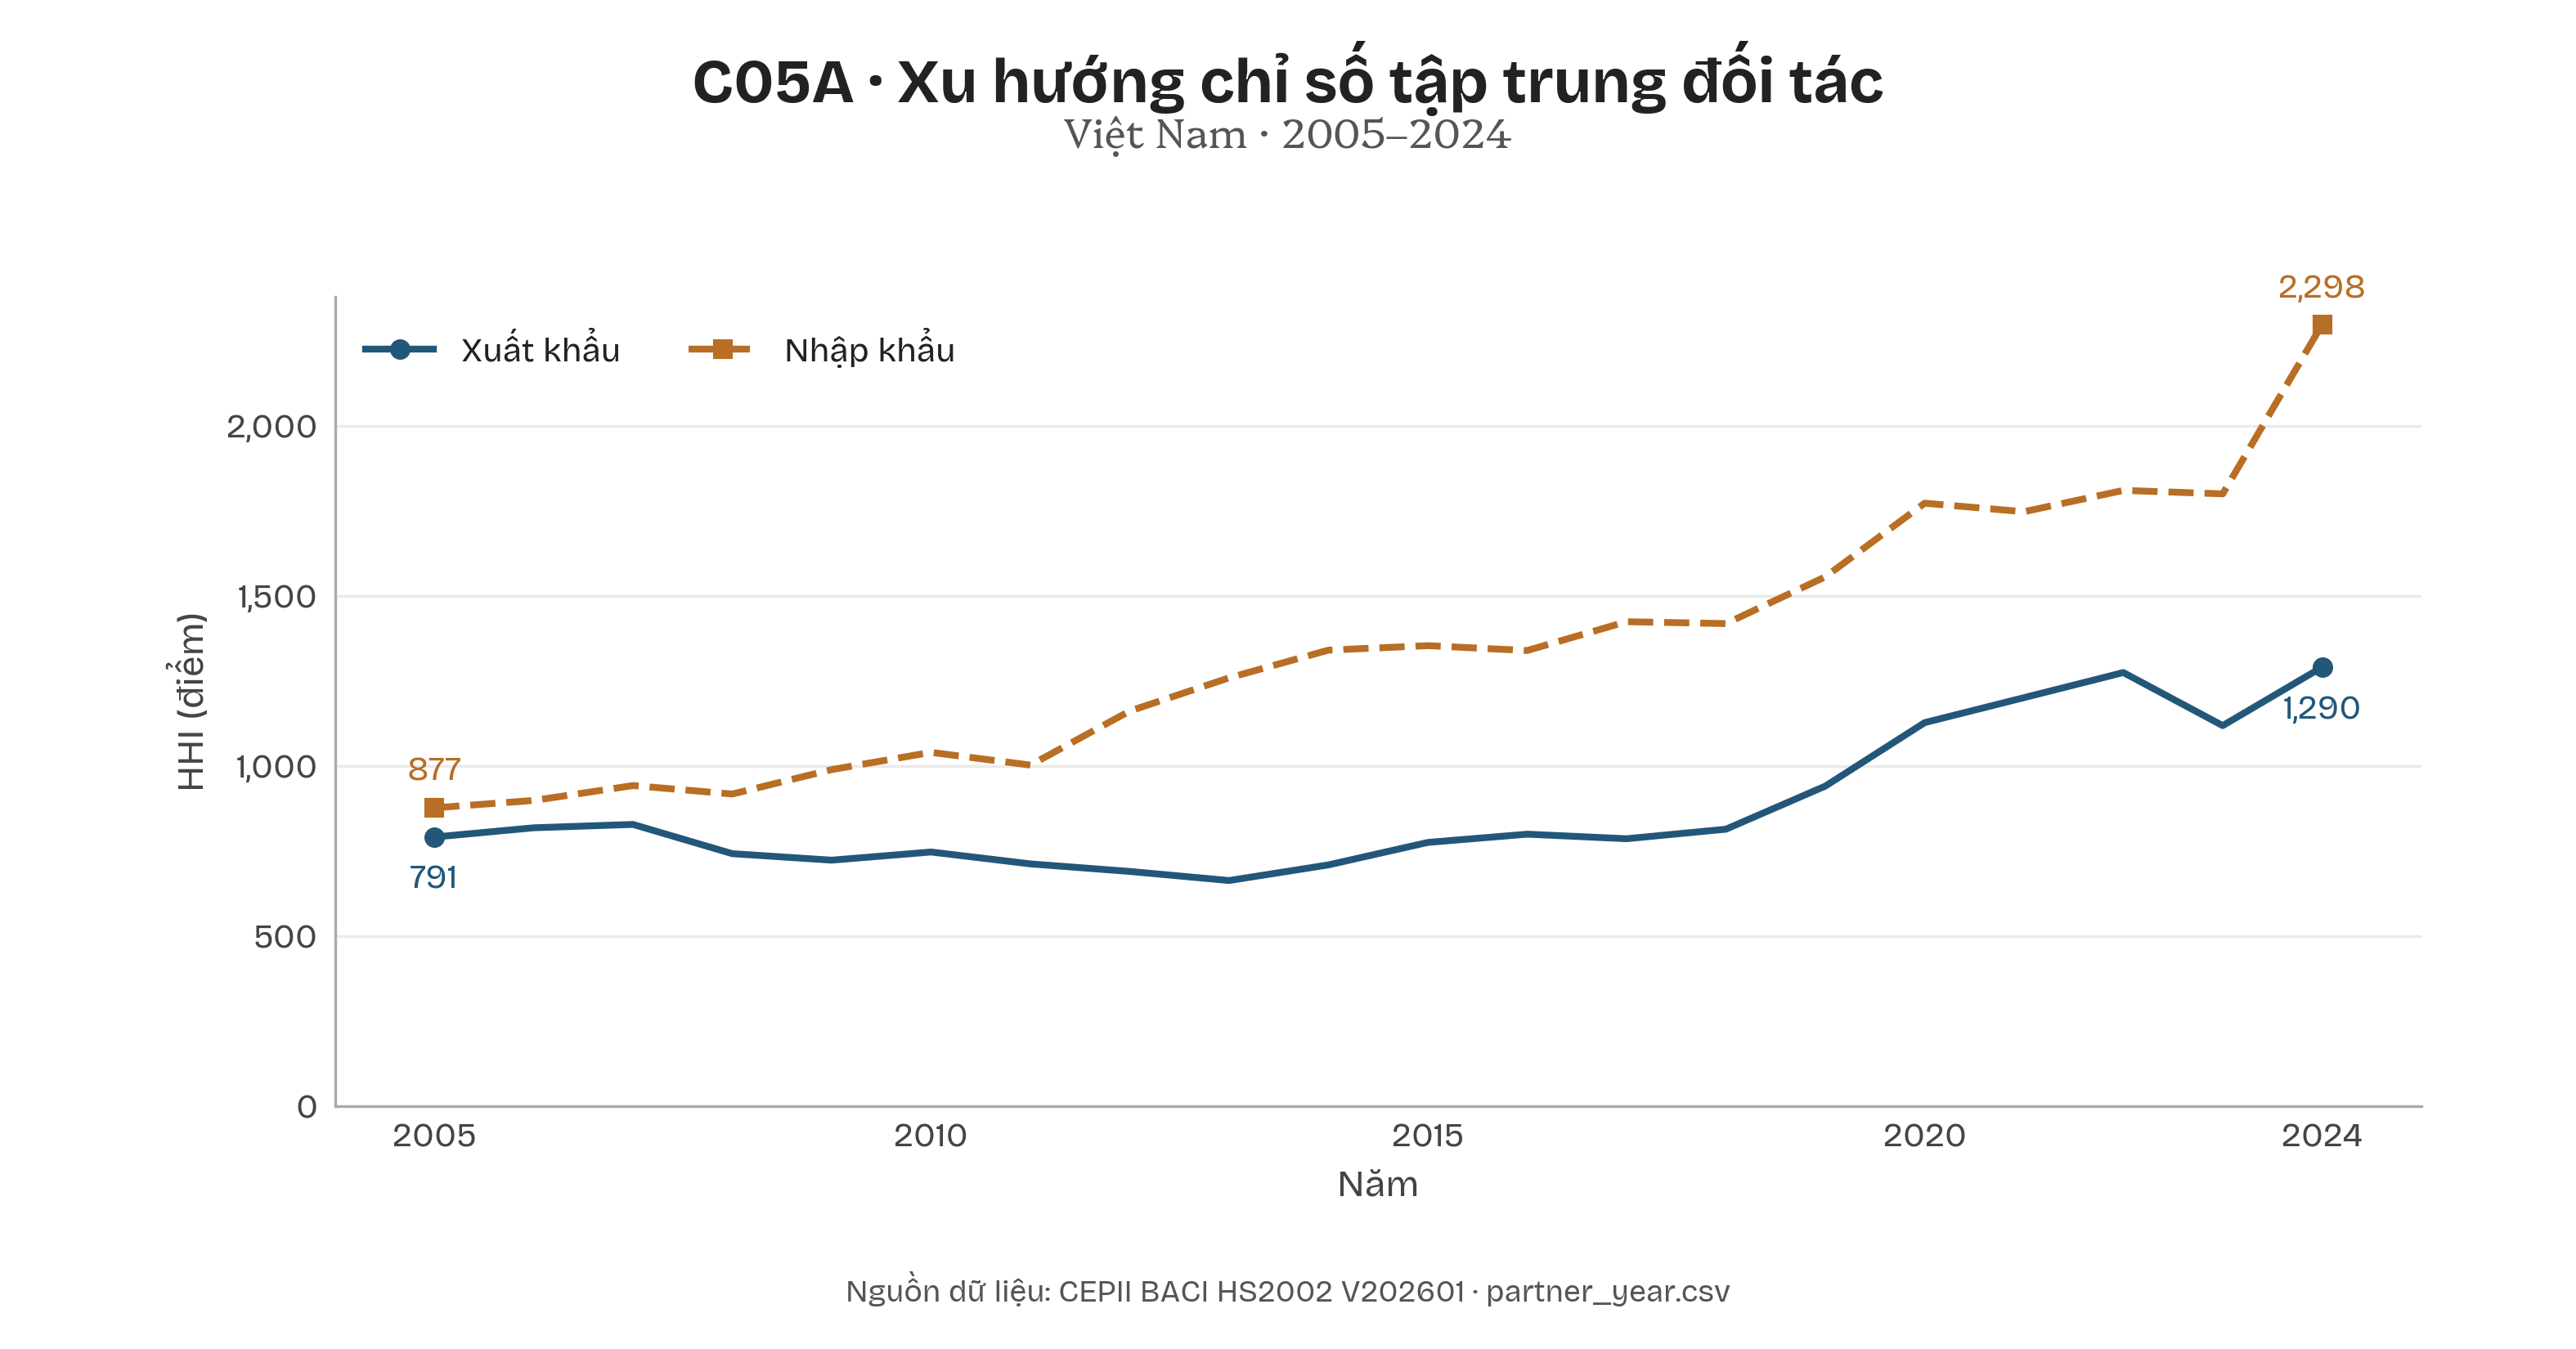

In [3]:
MA_BIEU_DO = "C05A"
fig = plot_c05(indices, "HHI", "C05A · Xu hướng chỉ số tập trung đối tác")
for line, flow in zip(fig.axes[0].lines, TRADE_FLOW_ORDER, strict=True):
    assert tuple(line.get_xdata()) == YEARS
    expected = indices["HHI"].xs(flow, level="trade_flow").reindex(YEARS)
    assert len(expected) == 20 and np.allclose(line.get_ydata(), expected)
format_value = format_percent if "HHI" == "CR5" else format_number
print(indices["HHI"].unstack().rename(columns=TRADE_FLOW_LABELS)
      .loc[[2005, 2024]].rename_axis(index="Năm", columns=None).apply(lambda col: col.map(format_value)))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C05A

HHI nhập khẩu tăng **1,421 điểm**, từ **877** năm 2005 lên **2,298** năm 2024.

## C05B · Tỷ trọng của năm đối tác lớn nhất

- **Task** · (Q2.3) Theo dõi CR5 xuất khẩu và nhập khẩu.
- **Dạng** · Biểu đồ đường 2005–2024, có nhãn ở hai đầu mỗi đường.
- **Lý do** · CR5 cho biết năm đối tác lớn nhất chiếm bao nhiêu phần trong tổng kim ngạch.
- **Xử lý** · Với mỗi năm và mỗi chiều, cộng tỷ trọng của năm đối tác đứng đầu. Hiển thị tỷ trọng dưới dạng phần trăm, với trục Y bắt đầu từ 0%.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

     Xuất khẩu Nhập khẩu
Năm                     
2005     52.1%     61.6%
2024     62.4%     74.4%
Đã lưu outputs/core_charts/C05/C05B.png và outputs/core_charts/C05/C05B.svg


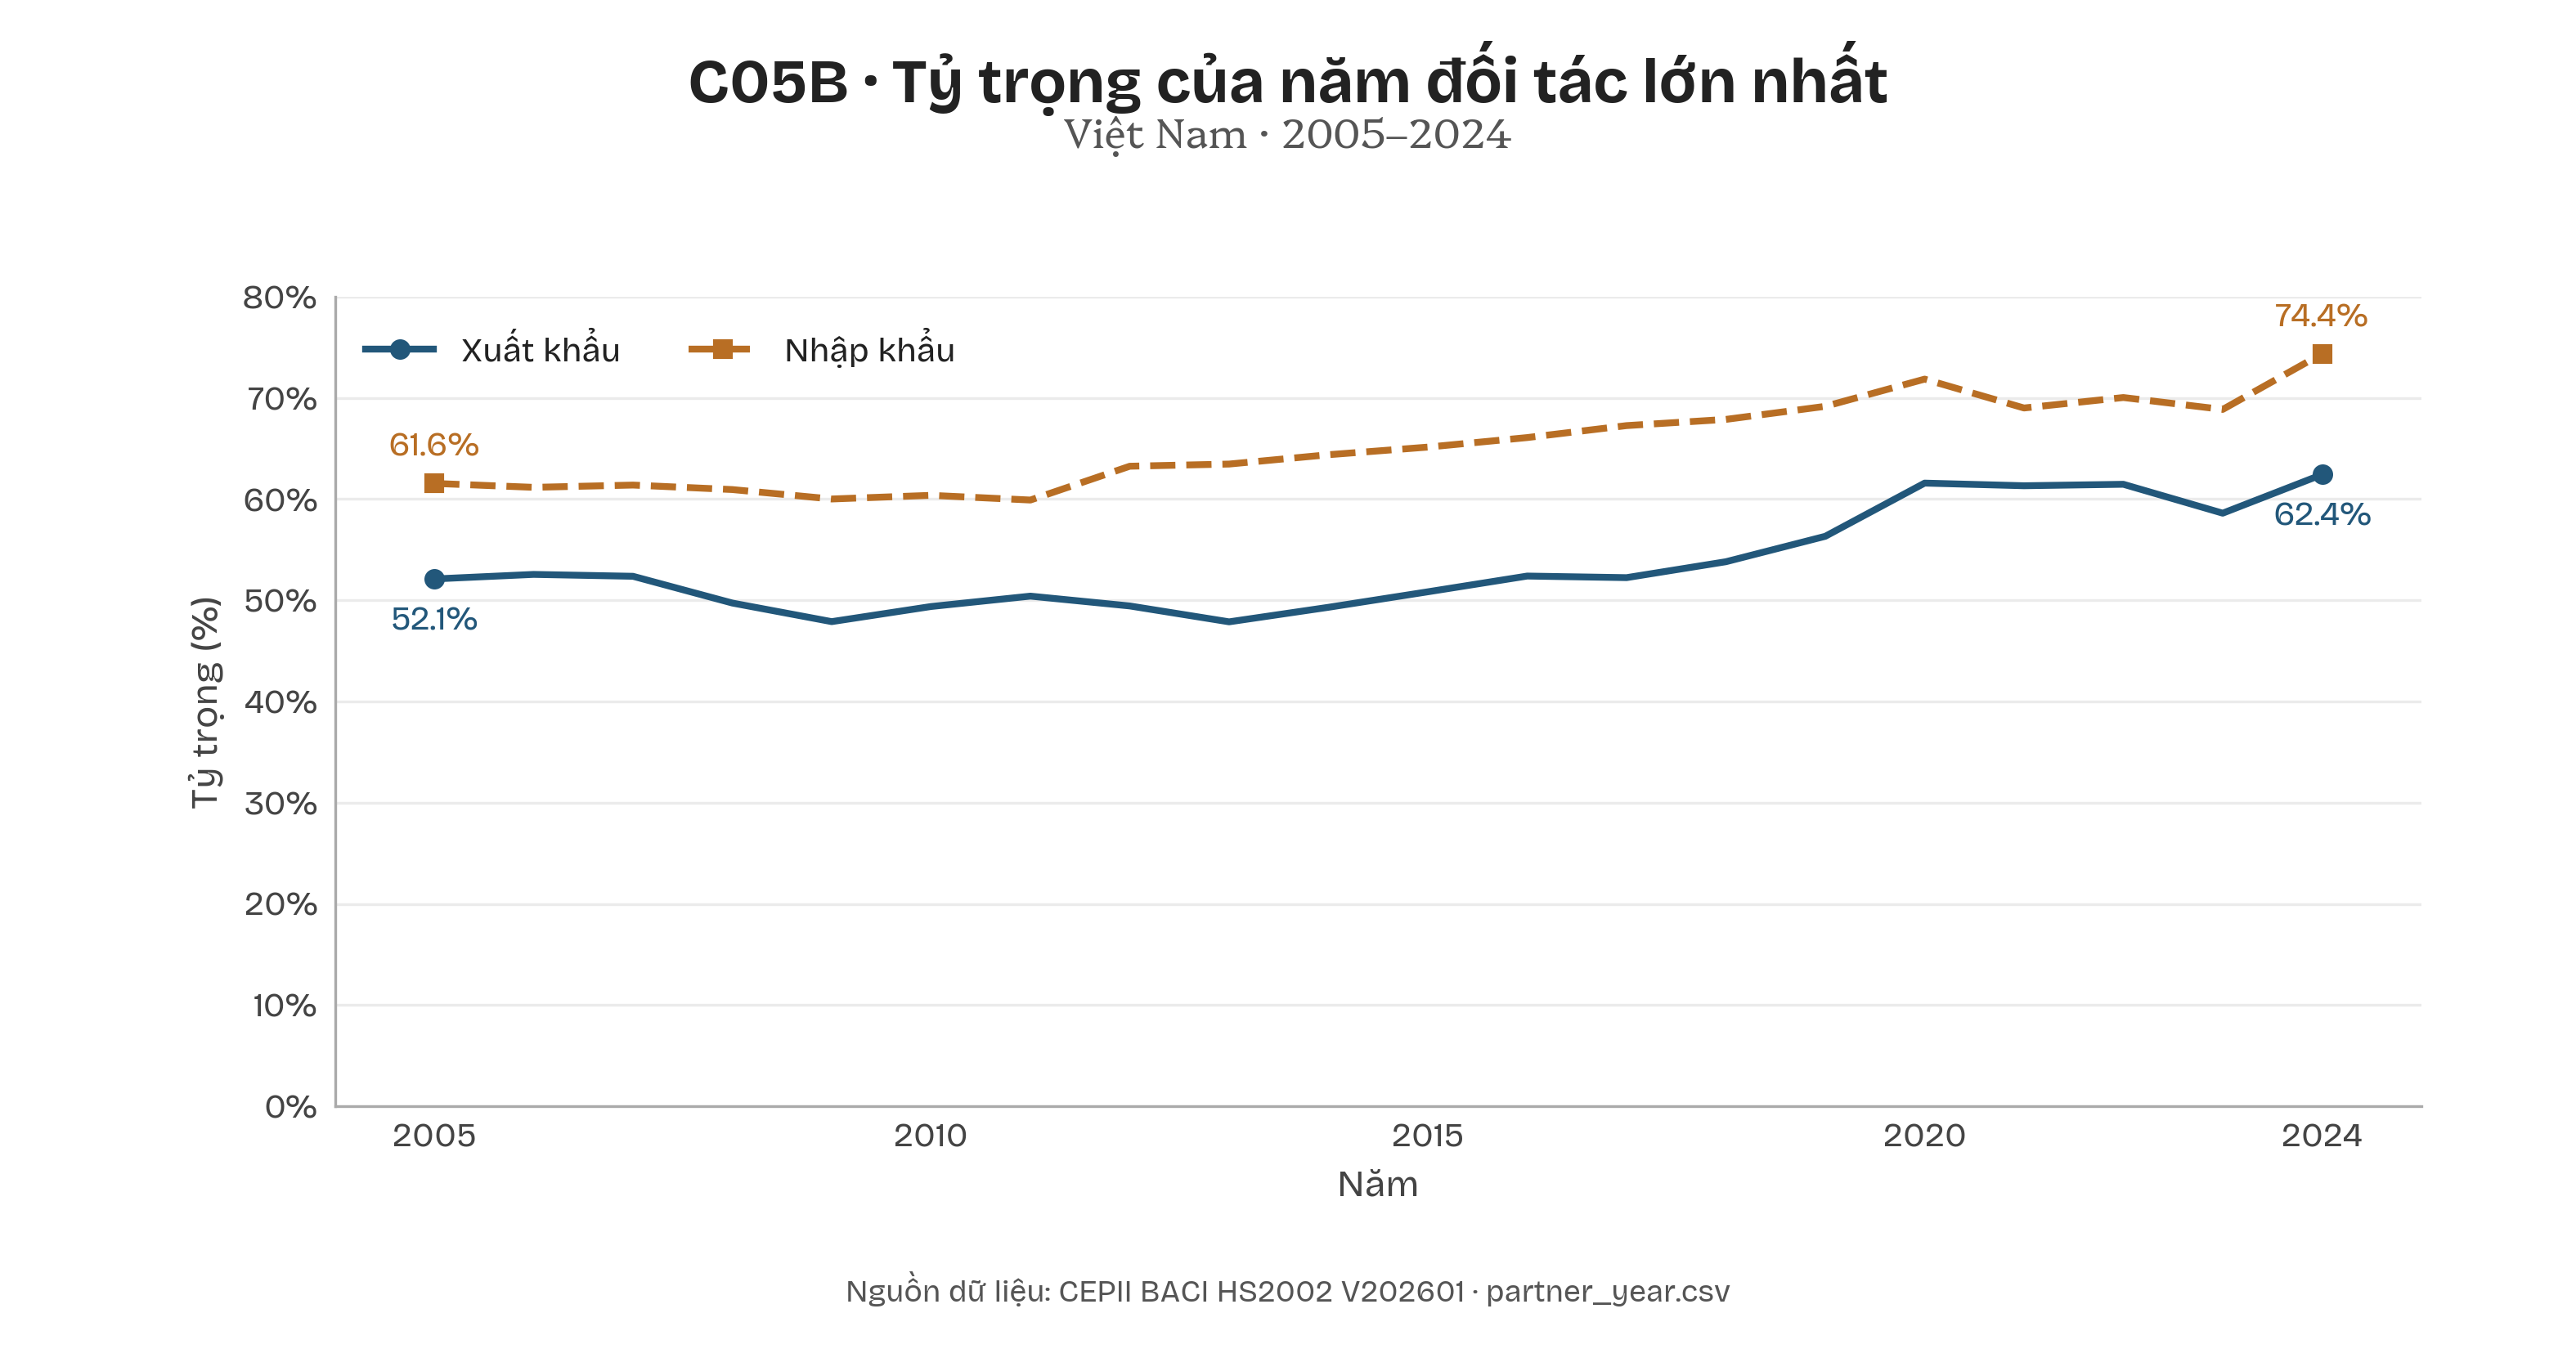

In [4]:
MA_BIEU_DO = "C05B"
fig = plot_c05(indices, "CR5", "C05B · Tỷ trọng của năm đối tác lớn nhất")
for line, flow in zip(fig.axes[0].lines, TRADE_FLOW_ORDER, strict=True):
    assert tuple(line.get_xdata()) == YEARS
    expected = indices["CR5"].xs(flow, level="trade_flow").reindex(YEARS)
    assert len(expected) == 20 and np.allclose(line.get_ydata(), expected)
format_value = format_percent if "CR5" == "CR5" else format_number
print(indices["CR5"].unstack().rename(columns=TRADE_FLOW_LABELS)
      .loc[[2005, 2024]].rename_axis(index="Năm", columns=None).apply(lambda col: col.map(format_value)))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C05B

Năm 2024, năm đối tác lớn nhất chiếm **62.4%** kim ngạch xuất khẩu và **74.4%** kim ngạch nhập khẩu.